## Step 1: Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

## Step 2: Load the Dataset
Dataset: Titanic (Kaggle) | File type: CSV | Source: https://www.kaggle.com/c/titanic/data

In [6]:


FILE_PATH = "Titanic.csv"      # change to your file name if needed

df_original = pd.read_csv(FILE_PATH)
print("Dataset loaded:", FILE_PATH)
print("Shape:", df_original.shape)
df_original.head()

Dataset loaded: Titanic.csv
Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 2.1 View First and Last 5 Rows

In [7]:
print("First 5 rows:")
display(df_original.head())
print("\nLast 5 rows:")
display(df_original.tail())

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Last 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


### 2.2 Rows, Columns, Column Names and Data Types

In [8]:
print("Rows    :", df_original.shape[0])
print("Columns :", df_original.shape[1])
print("\nColumn names:", list(df_original.columns))
print("\nData types:")
df_original.info()

Rows    : 891
Columns : 12

Column names: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## Step 3: Data Types and Basic Statistics
### 3.1 Separate Numerical and Categorical Columns

In [9]:
numerical_cols   = df_original.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df_original.select_dtypes(exclude=[np.number]).columns.tolist()
print("Numerical columns  :", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns  : ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


### 3.2 Summary Statistics

In [10]:
display(df_original[numerical_cols].describe().T)
display(df_original[categorical_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


,count,unique,top,freq
Name,891,891,"Dooley, Mr. Patrick",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


### 3.3 Check Suspicious Values and Unneeded Columns

In [11]:
print("Survived values:", df_original["Survived"].unique())
print("Pclass values  :", df_original["Pclass"].unique())
print("Sex values     :", df_original["Sex"].unique())
print("Embarked values:", df_original["Embarked"].unique())
print("\nRows with Fare = 0:", (df_original["Fare"] == 0).sum())
print("Min age:", df_original["Age"].min(), "| Max age:", df_original["Age"].max())
print("Unique names  :", df_original["Name"].nunique(), "of", len(df_original))
print("Unique tickets:", df_original["Ticket"].nunique(), "of", len(df_original))

Survived values: [0 1]
Pclass values  : [3 1 2]
Sex values     : ['male' 'female']
Embarked values: ['S' 'C' 'Q' nan]

Rows with Fare = 0: 15
Min age: 0.42 | Max age: 80.0
Unique names  : 891 of 891
Unique tickets: 681 of 891


## Step 4: Identify Missing Values
### 4.1 Missing Value Count and Percentage

In [12]:
missing_table = pd.DataFrame({
    "Missing Count": df_original.isnull().sum(),
    "Missing %": (df_original.isnull().sum() / len(df_original) * 100).round(2)
})
display(missing_table.sort_values("Missing %", ascending=False))

print("No missing values:", missing_table[missing_table["Missing Count"] == 0].index.tolist())
print("Need attention   :", missing_table[missing_table["Missing Count"] > 0].index.tolist())

,Missing Count,Missing %
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


No missing values: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'SibSp', 'Parch', 'Ticket', 'Fare']
Need attention   : ['Age', 'Cabin', 'Embarked']


### 4.2 Missing Values Heatmap

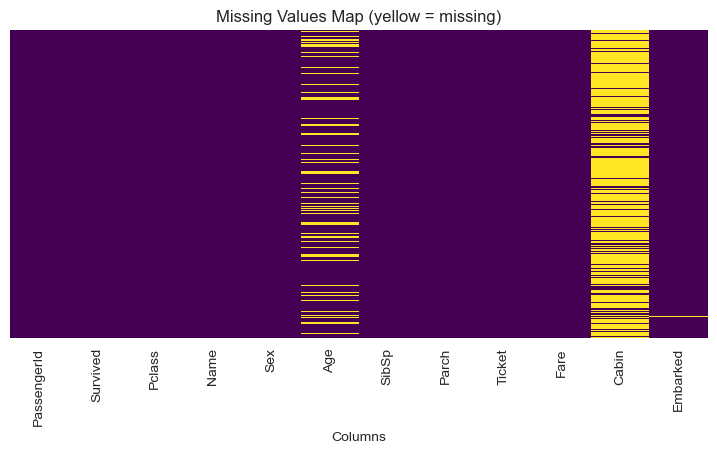

In [13]:
plt.figure(figsize=(9, 4))
sns.heatmap(df_original.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values Map (yellow = missing)")
plt.xlabel("Columns")
plt.show()

## Step 5: Handle Missing Values
### 5.1 Make a Copy of the Original Data

In [14]:
df = df_original.copy()      # work on a copy; the original stays unchanged
print("Missing BEFORE:\n", df.isnull().sum()[df.isnull().sum() > 0])

Missing BEFORE:
 Age         177
Cabin       687
Embarked      2
dtype: int64


### 5.2 Fill / Drop Missing Values (Cabin, Age, Embarked)

In [15]:
# 1) Cabin: ~77% missing -> too much to fill reliably, so drop the column
df = df.drop(columns=["Cabin"])

# 2) Age: numerical and skewed -> MEDIAN within each (Pclass, Sex) group
df["Age"] = df["Age"].fillna(df.groupby(["Pclass", "Sex"])["Age"].transform("median"))

# 3) Embarked: categorical, only 2 missing -> MODE
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print("Missing AFTER:\n", df.isnull().sum())
print("Total missing:", df.isnull().sum().sum())

Missing AFTER:
 PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64
Total missing: 0


## Step 6: Duplicate Records and Consistency
### 6.1 Check for Duplicate Records

In [16]:
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate PassengerId:", df["PassengerId"].duplicated().sum())
print("Duplicate Name       :", df["Name"].duplicated().sum())
print("Duplicate Ticket     :", df["Ticket"].duplicated().sum())
# Repeated tickets are genuine: families and groups shared one ticket.

Duplicate rows       : 0
Duplicate PassengerId: 0
Duplicate Name       : 0
Duplicate Ticket     : 210


### 6.2 Remove Duplicates and Fix Inconsistent Labels

In [17]:
before = len(df)
df = df.drop_duplicates()
print("Rows removed:", before - len(df))

for col in ["Sex", "Embarked"]:
    print(f"{col} before:", df[col].unique())
    df[col] = df[col].astype(str).str.strip()
df["Sex"] = df["Sex"].str.lower()
df["Embarked"] = df["Embarked"].str.upper()
for col in ["Sex", "Embarked"]:
    print(f"{col} after :", df[col].unique())

Rows removed: 0
Sex before: ['male' 'female']
Embarked before: ['S' 'C' 'Q']
Sex after : ['male' 'female']
Embarked after : ['S' 'C' 'Q']


### 6.3 Investigate Unusual Values (Fare = 0 and Outliers)

In [18]:
display(df[df["Fare"] == 0][["Pclass", "Name", "Age", "Fare", "Embarked"]].head(8))

Q1, Q3 = df["Fare"].quantile([0.25, 0.75])
upper = Q3 + 1.5 * (Q3 - Q1)
print(f"Fare IQR upper bound: {upper:.2f}")
print("Rows above bound:", (df["Fare"] > upper).sum(), "-> kept (genuine expensive 1st-class tickets)")

,Pclass,Name,Age,Fare,Embarked
179,3,"Leonard, Mr. Lionel",36.0,0.0,S
263,1,"Harrison, Mr. William",40.0,0.0,S
271,3,"Tornquist, Mr. William Henry",25.0,0.0,S
277,2,"Parkes, Mr. Francis ""Frank""",30.0,0.0,S
302,3,"Johnson, Mr. William Cahoone Jr",19.0,0.0,S
413,2,"Cunningham, Mr. Alfred Fleming",30.0,0.0,S
466,2,"Campbell, Mr. William",30.0,0.0,S
481,2,"Frost, Mr. Anthony Wood ""Archie""",30.0,0.0,S


Fare IQR upper bound: 65.63
Rows above bound: 116 -> kept (genuine expensive 1st-class tickets)


## Step 7: Exploratory Data Analysis (EDA)
### 7.1 Summary Statistics and Frequency Counts

In [19]:
display(df[["Age", "Fare", "SibSp", "Parch"]].describe().T)
print("\nSurvived:\n", df["Survived"].value_counts())
print("\nSex:\n", df["Sex"].value_counts())
print("\nPclass:\n", df["Pclass"].value_counts())
print("\nEmbarked:\n", df["Embarked"].value_counts())

,count,mean,std,min,25%,50%,75%,max
Age,891.0,29.112424,13.304424,0.42,21.5000,26.0000,36.0,80.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000



Survived:
 Survived
0    549
1    342
Name: count, dtype: int64

Sex:
 Sex
male      577
female    314
Name: count, dtype: int64

Pclass:
 Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Embarked:
 Embarked
S    646
C    168
Q     77
Name: count, dtype: int64


### 7.2 Histogram: Distribution of Age

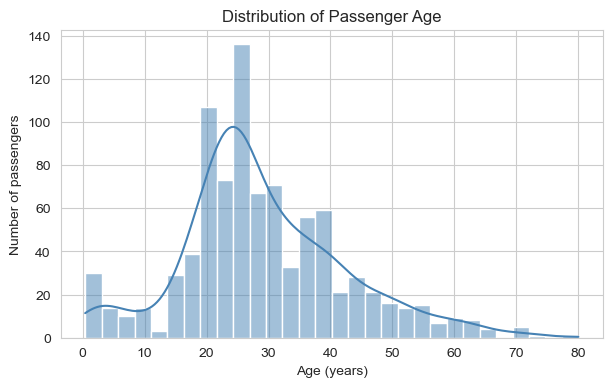

In [20]:
# Plot 1: Histogram of Age
plt.figure(figsize=(7, 4))
sns.histplot(df["Age"], bins=30, kde=True, color="steelblue")
plt.title("Distribution of Passenger Age")
plt.xlabel("Age (years)")
plt.ylabel("Number of passengers")
plt.show()

### 7.3 Bar Chart: Survival Count by Sex

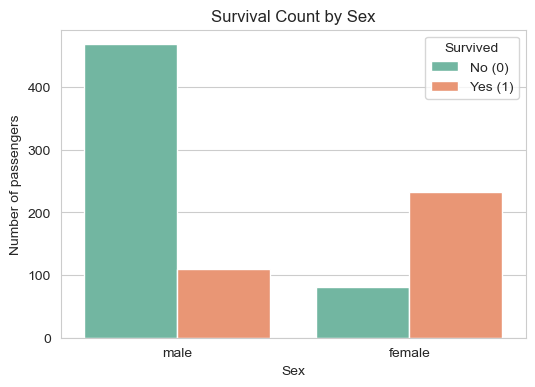

In [21]:
# Plot 2: Survival count by Sex
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Sex", hue="Survived", palette="Set2")
plt.title("Survival Count by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of passengers")
plt.legend(title="Survived", labels=["No (0)", "Yes (1)"])
plt.show()

### 7.4 Box Plot: Fare by Passenger Class

C:\Users\Sanika\AppData\Local\Temp\ipykernel_8800\3519852621.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Pclass", y="Fare", palette="Pastel1")


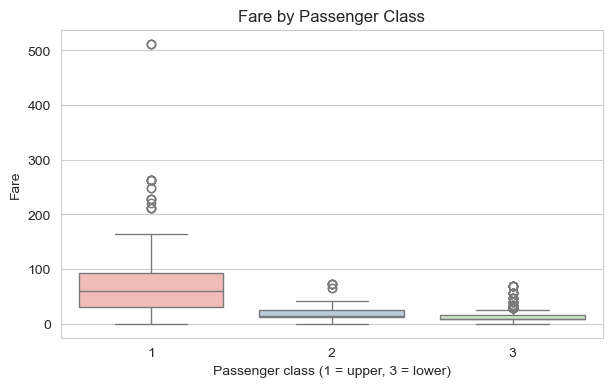

In [22]:
# Plot 3: Box plot of Fare by class
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Pclass", y="Fare", palette="Pastel1")
plt.title("Fare by Passenger Class")
plt.xlabel("Passenger class (1 = upper, 3 = lower)")
plt.ylabel("Fare")
plt.show()

### 7.5 Bar Chart: Survival Rate by Passenger Class

C:\Users\Sanika\AppData\Local\Temp\ipykernel_8800\992741054.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Pclass", y="Survived", palette="Blues_d", errorbar=None)


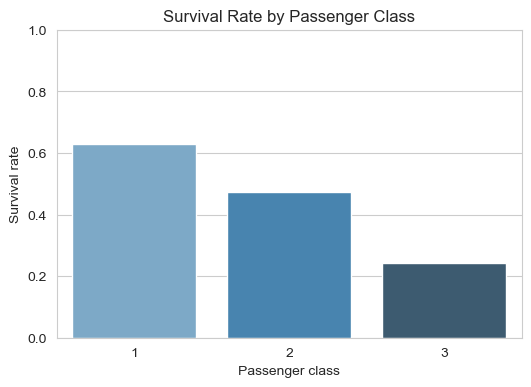

In [23]:
# Plot 4: Survival rate by class
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Pclass", y="Survived", palette="Blues_d", errorbar=None)
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger class")
plt.ylabel("Survival rate")
plt.ylim(0, 1)
plt.show()

### 7.6 Correlation Heatmap

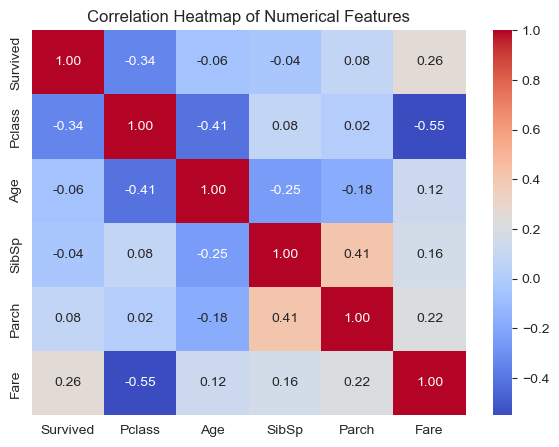

In [24]:
# Plot 5: Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### 7.7 Survival Rates by Sex and Class

In [25]:
print("Survival rate by Sex (%):\n", (df.groupby("Sex")["Survived"].mean() * 100).round(1))
print("\nSurvival rate by Pclass (%):\n", (df.groupby("Pclass")["Survived"].mean() * 100).round(1))

Survival rate by Sex (%):
 Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

Survival rate by Pclass (%):
 Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


## Step 8: Encode Categorical Features
### 8.1 Drop Identifier Columns and View Data Before Encoding

In [26]:
df_clean = df.drop(columns=["PassengerId", "Name", "Ticket"])
df_clean.to_csv("titanic_cleaned_not_encoded.csv", index=False)

print("Categorical columns left:", df_clean.select_dtypes(exclude=[np.number]).columns.tolist())
print("\nBEFORE encoding:")
display(df_clean[["Sex", "Embarked"]].head())

Categorical columns left: ['Sex', 'Embarked']

BEFORE encoding:


,Sex,Embarked
0,male,S
1,female,C
2,female,S
3,female,S
4,male,S


### 8.2 One-Hot Encoding (Sex, Embarked)

In [27]:
# Sex and Embarked are nominal -> one-hot encoding
df_encoded = pd.get_dummies(df_clean, columns=["Sex", "Embarked"], drop_first=True, dtype=int)
# Pclass is ordinal (1,2,3) and already numeric -> kept as is

print("AFTER encoding:")
display(df_encoded.head())
print("Columns:", list(df_encoded.columns))
print("Shape  :", df_encoded.shape)

AFTER encoding:


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


Columns: ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']
Shape  : (891, 9)


## Step 9: Scale Numerical Features
### 9.1 Check Different Scales

In [28]:
display(df_encoded[["Age", "SibSp", "Parch", "Fare"]].describe().loc[["min", "max", "mean", "std"]])

,Age,SibSp,Parch,Fare
min,0.420000,0.000000,0.000000,0.000000
max,80.000000,8.000000,6.000000,512.329200
mean,29.112424,0.523008,0.381594,32.204208
std,13.304424,1.102743,0.806057,49.693429


### 9.2 Train-Test Split and Standardisation (Scaler Fitted on Train Only)

In [29]:
X = df_encoded.drop(columns=["Survived"])
y = df_encoded["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

cols_to_scale = ["Age", "SibSp", "Parch", "Fare"]   # NOT target, NOT 0/1 columns, NOT Pclass
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()
X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])  # learn from TRAIN only
X_test_scaled[cols_to_scale]  = scaler.transform(X_test[cols_to_scale])       # only apply to TEST

print("\nTrain mean after scaling (~0):\n", X_train_scaled[cols_to_scale].mean().round(3))
print("\nTrain std after scaling (~1):\n", X_train_scaled[cols_to_scale].std().round(3))

Train: (712, 8) | Test: (179, 8)

Train mean after scaling (~0):
 Age      0.0
SibSp   -0.0
Parch   -0.0
Fare    -0.0
dtype: float64

Train std after scaling (~1):
 Age      1.001
SibSp    1.001
Parch    1.001
Fare     1.001
dtype: float64


### 9.3 Before vs After Scaling Comparison

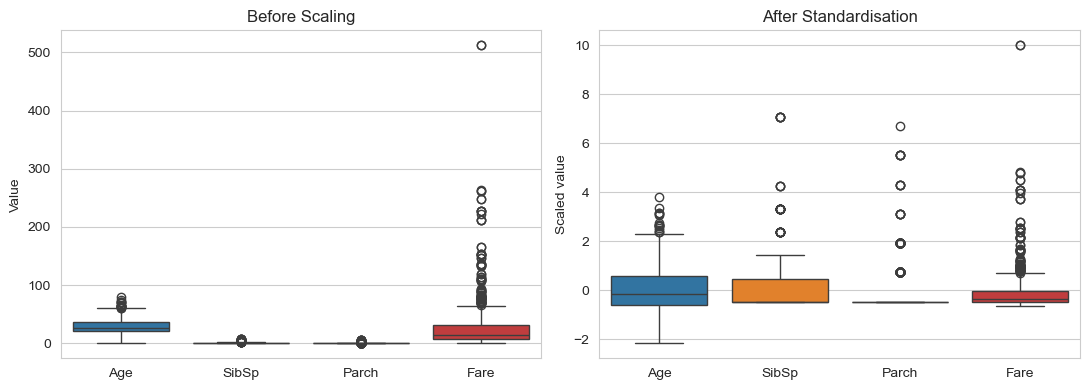

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=X_train[cols_to_scale], ax=axes[0])
axes[0].set_title("Before Scaling")
axes[0].set_ylabel("Value")
sns.boxplot(data=X_train_scaled[cols_to_scale], ax=axes[1])
axes[1].set_title("After Standardisation")
axes[1].set_ylabel("Scaled value")
plt.tight_layout()
plt.show()

## Step 10: Save the Prepared Dataset
### 10.1 Combine Data and Run Final Checks

In [31]:
train_part = X_train_scaled.assign(Survived=y_train, Split="train")
test_part  = X_test_scaled.assign(Survived=y_test, Split="test")
df_final = pd.concat([train_part, test_part]).sort_index()

print("Final shape         :", df_final.shape)
print("Remaining missing   :", df_final.isnull().sum().sum())
print("Remaining duplicates:", df_final.drop(columns="Split").duplicated().sum())
print("\nData types:\n", df_final.dtypes)

Final shape         : (891, 10)
Remaining missing   : 0
Remaining duplicates: 118

Data types:
 Pclass          int64
Age           float64
SibSp         float64
Parch         float64
Fare          float64
Sex_male        int64
Embarked_Q      int64
Embarked_S      int64
Survived        int64
Split          object
dtype: object


### 10.2 Save Prepared Dataset as CSV

In [32]:
file_name = "titanic_prepared.csv"
df_final.to_csv(file_name, index=False)
print("Saved:", file_name)
display(pd.read_csv(file_name).head(10))

Saved: titanic_prepared.csv


,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Survived,Split
0,3,-0.547636,0.478335,-0.466183,-0.511601,1,0,1,0,train
1,1,0.654786,0.478335,-0.466183,0.821722,0,0,0,1,train
2,3,-0.247031,-0.465084,-0.466183,-0.497546,0,0,1,1,train
3,1,0.429332,0.478335,-0.466183,0.443103,0,0,1,1,train
4,3,0.429332,-0.465084,-0.466183,-0.494943,1,0,1,0,test
5,3,-0.322182,-0.465084,-0.466183,-0.486442,1,1,0,0,train
6,1,1.857208,-0.465084,-0.466183,0.417335,1,0,1,0,train
7,3,-2.050664,2.365172,0.727782,-0.223732,1,0,1,0,train
8,3,-0.171879,-0.465084,1.921748,-0.430742,0,0,1,1,train
9,2,-1.148847,0.478335,-0.466183,-0.036419,0,0,0,1,test


## Conclusion


In [ ]:
## Conclusion

**Dataset:** I used the Titanic passenger dataset (Kaggle, CSV file) with 891 rows and 12 columns. Each row is one passenger, and it has both numerical and categorical features. The column `Survived` could be used as the target in a future prediction task.

**Problems found:**
- `Cabin` was about 77% missing, `Age` about 20% missing, and `Embarked` had 2 missing values.
- `PassengerId`, `Name` and `Ticket` are identifier-type columns that don't help general analysis.
- `Fare` was highly skewed with many high values, and some passengers had `Fare = 0`.
- `Sex` and `Embarked` were text columns, so they can't be used directly by ML algorithms.
- `Age`, `Fare`, `SibSp` and `Parch` were on very different scales.
- There were no exact duplicate rows. Repeated ticket numbers were genuine, because families travelled on one ticket.

**How the data was prepared:**
- I worked on a copy, so the original data stayed unchanged.
- I dropped `Cabin` because too much of it was missing to fill reliably.
- I filled `Age` with the median of each Pclass and Sex group, because Age is skewed. I filled `Embarked` with the mode because it is categorical.
- I kept the outliers and zero fares after investigating them, because they looked like genuine observations.
- I dropped `PassengerId`, `Name` and `Ticket`.
- I one-hot encoded `Sex` and `Embarked`, and kept `Pclass` as an ordinal numeric feature.
- I standardised `Age`, `SibSp`, `Parch` and `Fare`, fitting the scaler on the training data only to avoid data leakage.
- I did not scale the target `Survived` or the 0/1 encoded columns.

**Key findings from EDA:** Most passengers were aged between about 20 and 40. Women survived much more often than men (about 74% against about 19%). Survival fell with passenger class (about 63% in 1st class, 47% in 2nd and 24% in 3rd).

**Final output:** The prepared dataset has no missing values, only numerical columns, and is saved as `titanic_prepared.csv`. It is ready for a machine learning workflow. The 118 duplicate rows reported at the end are different passengers who look identical once their ID, name and ticket are removed, so I kept them.